# Dữ liệu chất lượng rượu đỏ (Red Wine Quality)
**Nguồn trong đề:** Lab 1 — bài tập 1.1.3 và 1.2

Notebook độc lập cho một tập dữ liệu; code lấy từ các ô tương ứng của notebook Lab1 (giữ nguyên, ô nào chỉnh có ghi `# [Chỉnh]`).

In [1]:
# Thư viện dùng chung (đề import rải rác ở nhiều ô; gom lại để notebook chạy độc lập)
import os
if os.path.basename(os.getcwd()) == 'notebooks':   # chạy notebook từ thư mục notebooks/ thì lùi ra thư mục gốc chứa data/
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
import numpy as np
import pandas as pd
from scipy import stats
wine = pd.read_csv("data/winequality-red.csv", sep=';')
print(wine.shape)
wine.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
wine.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [4]:
wine.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [5]:
wine.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [6]:
# Các thước đo thống kê mô tả cho một số cột (ví dụ: alcohol)
col = wine['alcohol']
print("mean      :", np.mean(col))
print("median    :", np.median(col))
print("mode      :", stats.mode(col).mode)
print("variance  :", np.var(col))
print("std       :", np.std(col))
print("range     :", np.max(col) - np.min(col))
print("P60       :", np.percentile(col, 60))
print("Q1,Q2,Q3  :", np.quantile(col, [0.25, 0.5, 0.75]))
print("IQR       :", stats.iqr(col))
print("skewness  :", stats.skew(col))

mean      : 10.422983114446529
median    : 10.2
mode      : 9.5
variance  : 1.1349371714889036
std       : 1.0653343003437483
range     : 6.5
P60       : 10.5
Q1,Q2,Q3  : [ 9.5 10.2 11.1]
IQR       : 1.5999999999999996
skewness  : 0.8600210646566755


In [7]:
# Phân bố của biến mục tiêu quality và độ lệch (skewness) của các biến
print(wine['quality'].value_counts().sort_index())
wine.skew().sort_values(ascending=False)

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


chlorides               5.680347
residual sugar          4.540655
sulphates               2.428672
total sulfur dioxide    1.515531
free sulfur dioxide     1.250567
fixed acidity           0.982751
alcohol                 0.860829
volatile acidity        0.671593
citric acid             0.318337
quality                 0.217802
pH                      0.193683
density                 0.071288
dtype: float64

In [8]:
# Phát hiện ngoại lai bằng quy tắc 1.5*IQR
Q1 = wine.quantile(0.25); Q3 = wine.quantile(0.75); IQR = Q3 - Q1
outliers = ((wine < (Q1 - 1.5*IQR)) | (wine > (Q3 + 1.5*IQR))).sum()
outliers.sort_values(ascending=False)

residual sugar          155
chlorides               112
sulphates                59
total sulfur dioxide     55
fixed acidity            49
density                  45
pH                       35
free sulfur dioxide      30
quality                  28
volatile acidity         19
alcohol                  13
citric acid               1
dtype: int64

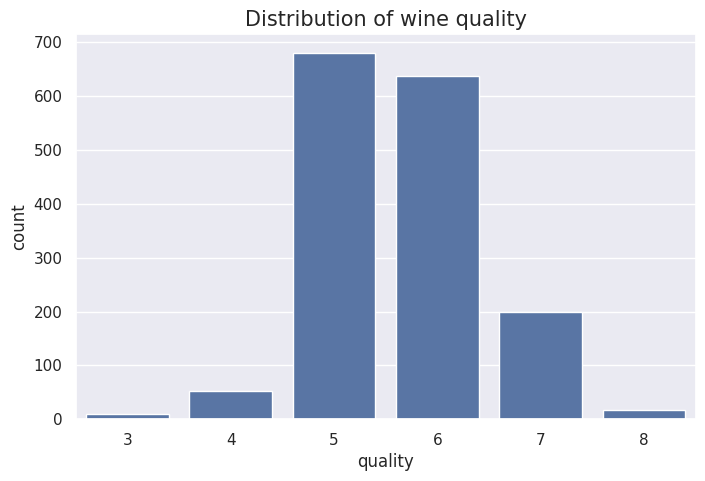

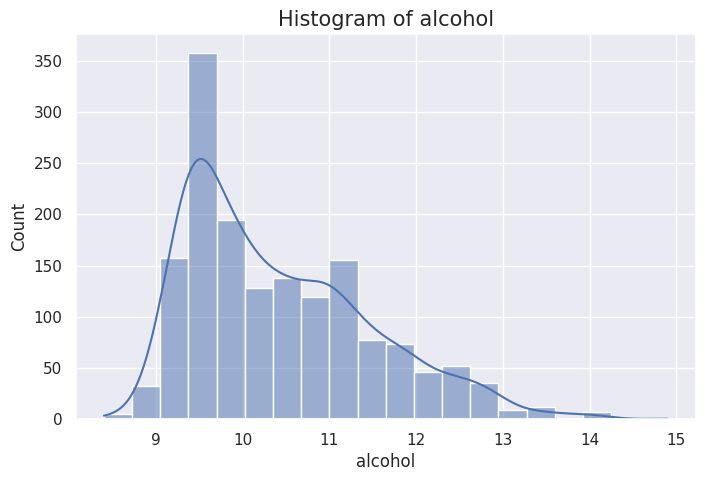

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()   # đưa style về mặc định sau khi đặt font_scale ở trên
wine = pd.read_csv("data/winequality-red.csv", sep=';')

# 1. Biểu đồ cột: phân bố chất lượng rượu
plt.figure(figsize=(8,5))
ax = sns.countplot(data=wine, x='quality')
ax.set_title('Distribution of wine quality', fontsize=15)
plt.show()

# 2. Histogram của nồng độ cồn
plt.figure(figsize=(8,5))
ax = sns.histplot(data=wine, x='alcohol', bins=20, kde=True)
ax.set_title('Histogram of alcohol', fontsize=15)
plt.show()

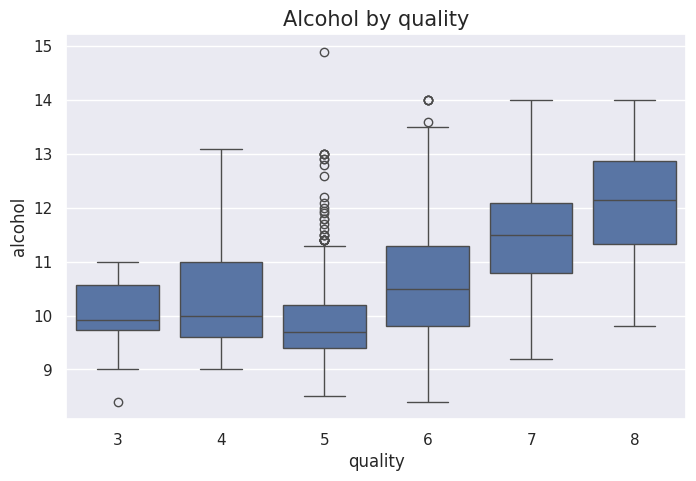

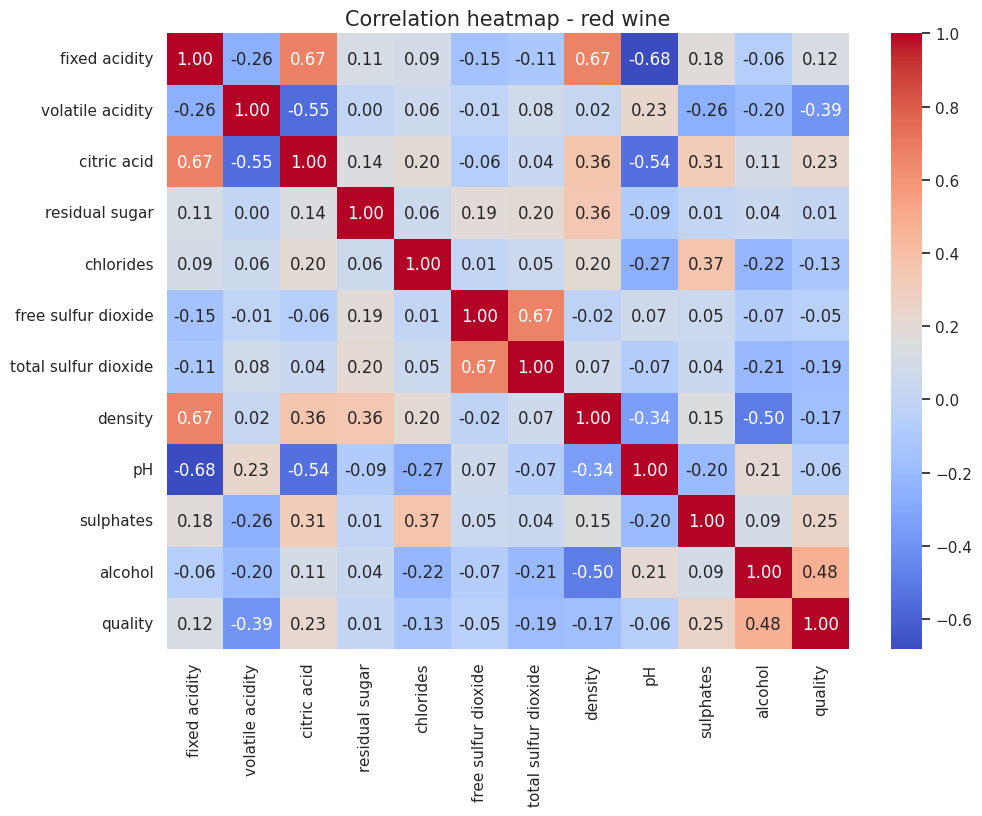

In [10]:
# 3. Boxplot alcohol theo quality (biến số vs biến phân loại)
plt.figure(figsize=(8,5))
ax = sns.boxplot(data=wine, x='quality', y='alcohol')
ax.set_title('Alcohol by quality', fontsize=15)
plt.show()

# 4. Heatmap tương quan giữa các biến
plt.figure(figsize=(11,8))
ax = sns.heatmap(wine.corr(), annot=True, fmt='.2f', cmap='coolwarm')
ax.set_title('Correlation heatmap - red wine', fontsize=15)
plt.show()